<a href="https://colab.research.google.com/github/Feri1977/Dicoding_Data_Analyst/blob/main/Clustering_Fraud_Detection_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **DATASET INFORMATION**
This dataset provides an in-depth look at transaction behavior and financial activity patterns, making it ideal for fraud detection and anomaly identification. The dataset includes 2,512 transaction data samples, covering a wide range of transaction attributes, customer demographics, and usage patterns.

Each entry provides comprehensive insights into transaction behavior, enabling analysis for financial security and predictive model development.

## Key Features

- **`TransactionID`**: A unique alphanumeric identifier for each transaction.  
- **`AccountID`**: Unique ID for each account, can have multiple transactions.  
- **`TransactionAmount`**: Transaction values ​​in currency, ranging from small expenses to large purchases.  
- **`TransactionDate`**: Date and Time of transactions.  
- **`TransactionType`**: Transaction types are `'Credit'` atau `'Debit'`.  
- **`Location`**: Geographic location of the transaction (city name in the United States).  
- **`DeviceID`**: Device ID used in the transaction.  
- **`IP Address`**: The IPv4 address used during transactions may change for some accounts.  
- **`MerchantID`**: Unique merchant ID, indicating primary merchant and transaction anomalies.  
- **`AccountBalance`**: Account balance after the transaction takes place.  
- **`PreviousTransactionDate`**: The last transaction date on the account, for calculating transaction frequency.  
- **`Channel`**: Transaction channels such as `Online`, `ATM`, or `Branch`.  
- **`CustomerAge`**: Age of account owner.  
- **`CustomerOccupation`**: User professions such as `Doctor`, `Engineer`, `Student`, or `Retired`.  
- **`TransactionDuration`**: Transaction time (seconds).  
- **`LoginAttempts`**: Number of login attempts before a transaction—a high number could indicate an anomaly.

# **1. Import Library**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from yellowbrick.cluster import KElbowVisualizer
import joblib

# **2. Loading Dataset**

In [2]:
# Load data

url='https://docs.google.com/spreadsheets/d/e/2PACX-1vTbg5WVW6W3c8SPNUGc3A3AL-AG32TPEQGpdzARfNICMsLFI0LQj0jporhsLCeVhkN5AoRsTkn08AYl/pub?output=csv'
df = pd.read_csv(url)

In [3]:
# Display the first 5 lines with the head function.

df.head()

,TransactionID,AccountID,TransactionAmount,PreviousTransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70.0,Doctor,81.0,1.0,5112.21,2024-11-04 8:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68.0,Doctor,141.0,1.0,13758.91,2024-11-04 8:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19.0,Student,56.0,1.0,1122.35,2024-11-04 8:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26.0,Student,25.0,1.0,8569.06,2024-11-04 8:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,NaN,Student,198.0,1.0,7429.40,2024-11-04 8:06:39


In [4]:
# Review the number of rows columns and data types in the dataset with info.

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2537 entries, 0 to 2536
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2508 non-null   object 
 1   AccountID                2516 non-null   object 
 2   TransactionAmount        2511 non-null   float64
 3   PreviousTransactionDate  2509 non-null   object 
 4   TransactionType          2507 non-null   object 
 5   Location                 2507 non-null   object 
 6   DeviceID                 2507 non-null   object 
 7   IP Address               2517 non-null   object 
 8   MerchantID               2514 non-null   object 
 9   Channel                  2510 non-null   object 
 10  CustomerAge              2519 non-null   float64
 11  CustomerOccupation       2514 non-null   object 
 12  TransactionDuration      2511 non-null   float64
 13  LoginAttempts            2516 non-null   float64
 14  AccountBalance          

In [5]:
# Display descriptive statistics of a dataset

df.describe()

,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance
count,2511.000000,2519.000000,2511.000000,2516.000000,2510.000000
mean,297.656468,44.678444,119.422939,1.121622,5113.438124
std,292.230367,17.837359,70.078513,0.594469,3897.975861
min,0.260000,18.000000,10.000000,1.000000,101.250000
25%,81.310000,27.000000,63.000000,1.000000,1504.727500
50%,211.360000,45.000000,112.000000,1.000000,4734.110000
75%,413.105000,59.000000,161.000000,1.000000,7672.687500
max,1919.110000,80.000000,300.000000,5.000000,14977.990000


In [6]:
# Selecting a numeric column
numerical_cols = df.select_dtypes(include=['number']).columns

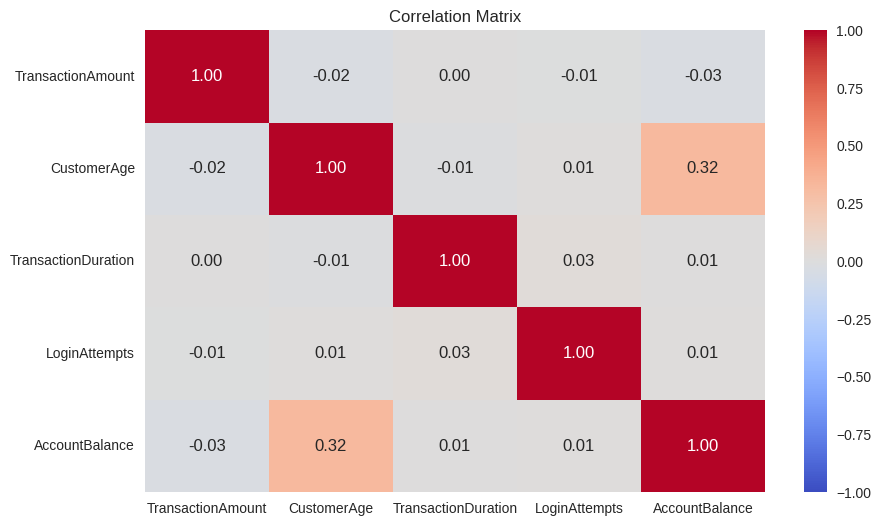

In [7]:
# Showing correlation between features

# Calculate the correlation matrix
correlation = df[numerical_cols].corr()

# Create a heatmap visualization
plt.figure(figsize=(10, 6))
sns.heatmap(correlation,
               annot=True,
               cmap='coolwarm',
               fmt=".2f",
               vmin=-1,
               vmax=1)
plt.title('Correlation Matrix')
plt.show()

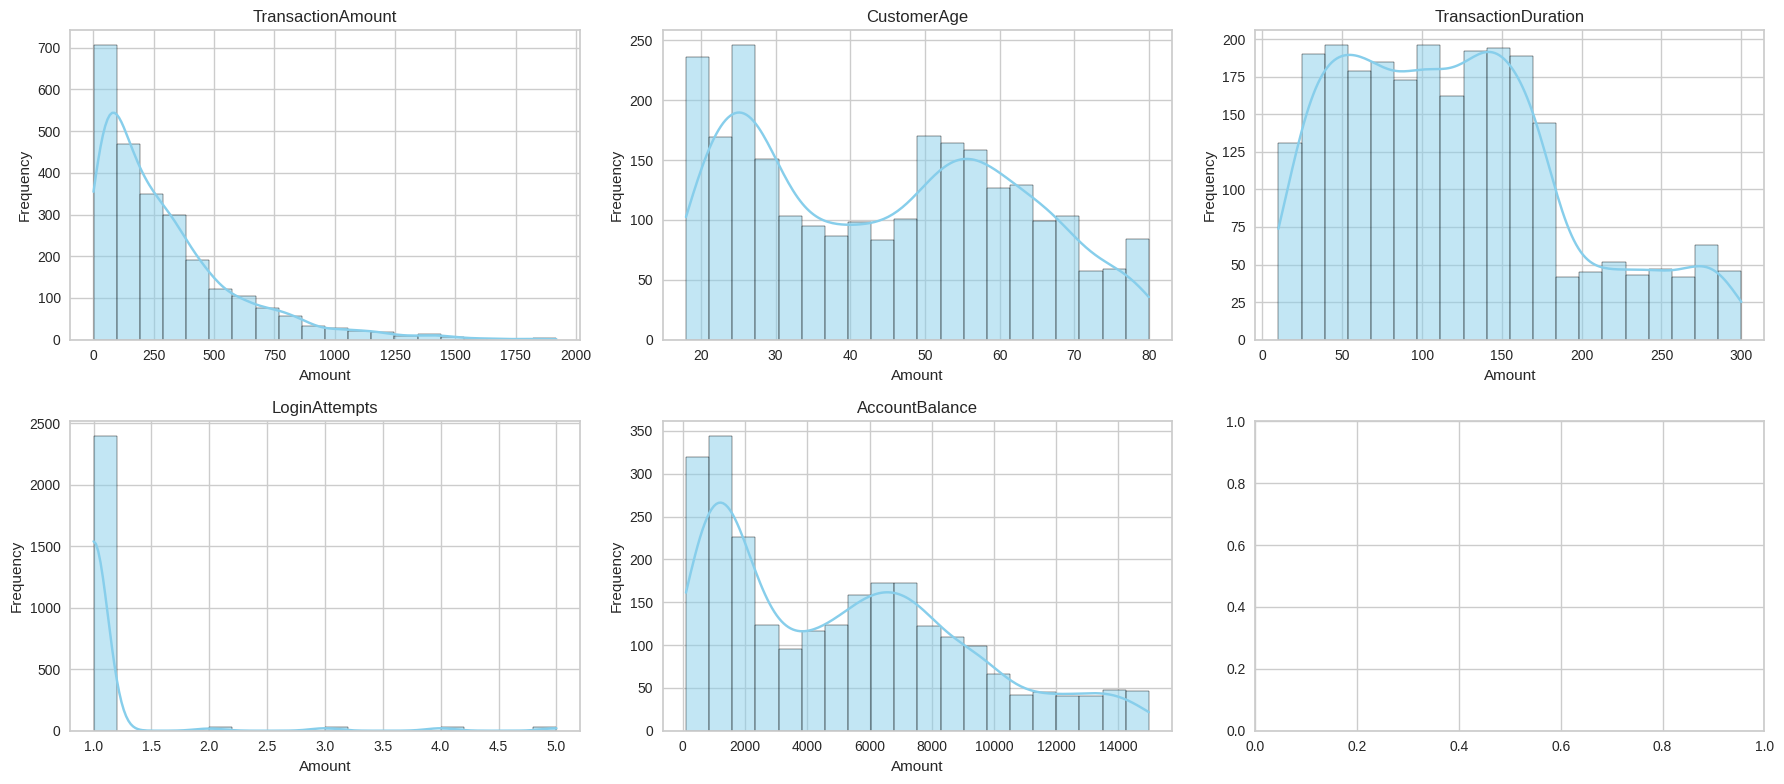

In [8]:
# Displays histograms for all numeric columns

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
axes = axes.flatten()

for i, column in enumerate(numerical_cols):

    # Display the histogram and make sure the plot is placed on the correct subplot (axes).
    sns.histplot(df[column], bins=20, kde=True, color='skyblue', ax=axes[i])

    # Setting title and labels
    axes[i].set_title(column)
    axes[i].set_xlabel("Amount")
    axes[i].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

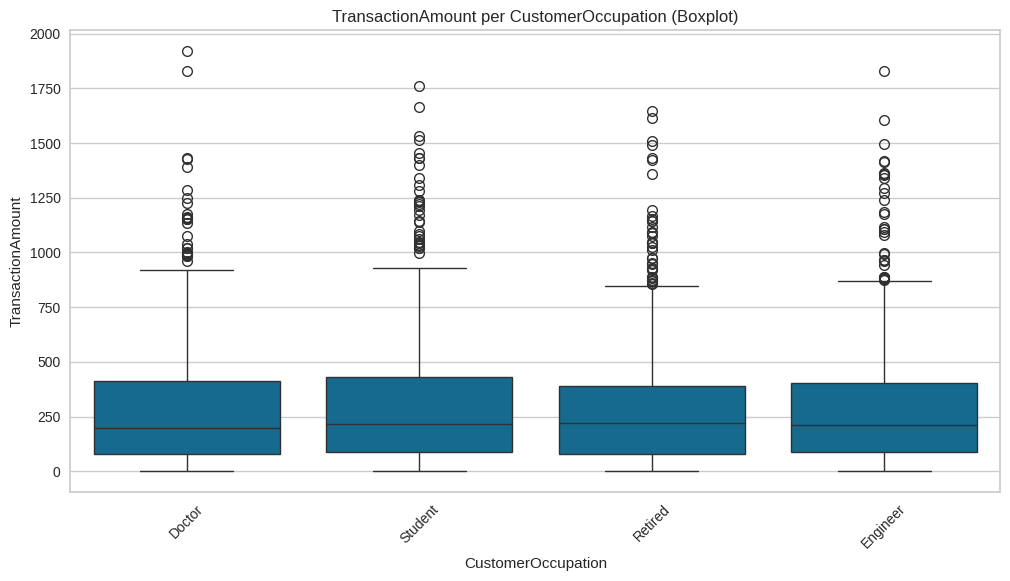

In [9]:
# More informative visualizations

plt.figure(figsize=(12, 6))

# Create a boxplot visualization to see the distribution of 'TransactionAmount' (y) based on 'CustomerOccupation' (x)
sns.boxplot(x='CustomerOccupation', y='TransactionAmount', data=df)

plt.title("TransactionAmount per CustomerOccupation (Boxplot)")

# Rotate the x-axis labels so they don't overlap
plt.xticks(rotation=45)

plt.show()

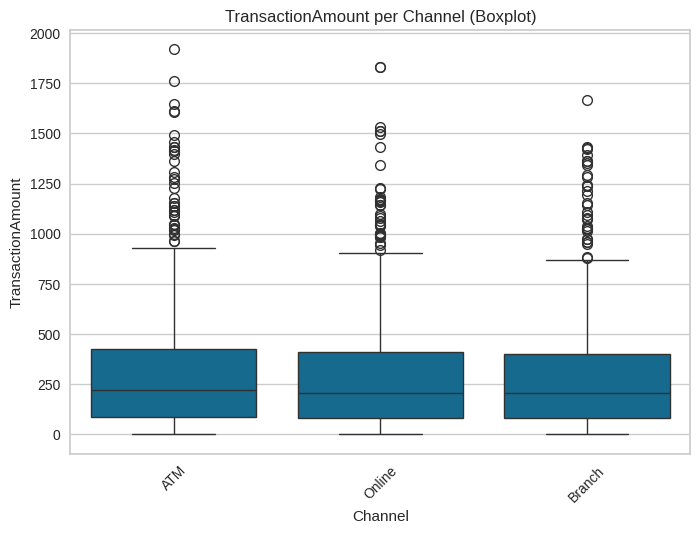

In [10]:
# Create a boxplot visualization to show the distribution of 'TransactionAmount' (y) based on 'Channel' (x)


sns.boxplot(x='Channel', y='TransactionAmount', data=df)

plt.title("TransactionAmount per Channel (Boxplot)")

# Rotate the x-axis labels so they don't overlap
plt.xticks(rotation=45)

plt.show()

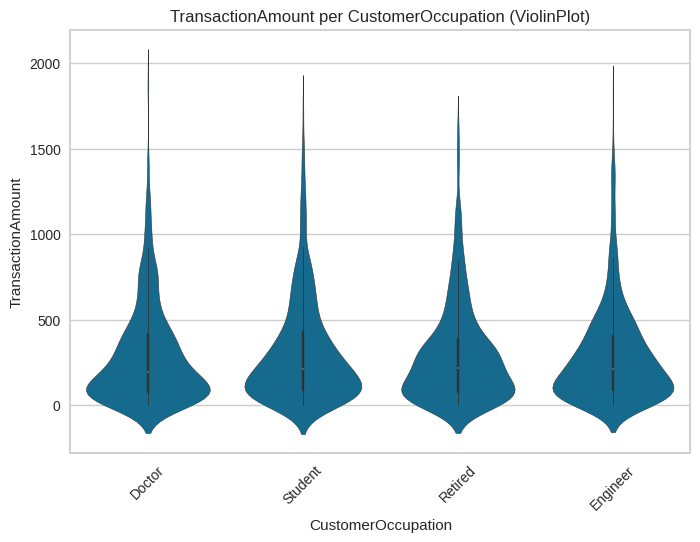

In [11]:
# Try creating another visualization below, for example 'violinplot' (sns.violinplot) with the parameters of CustomerOccupation and TransactionAmount
sns.violinplot(x='CustomerOccupation', y='TransactionAmount', data=df)

plt.title("TransactionAmount per CustomerOccupation (ViolinPlot)")

# Rotate the x-axis labels so they don't overlap
plt.xticks(rotation=45)

plt.show()

# **3. Data Cleaning and Preprocessing**

**Dataset Cleaning** will be performed to make the dataset easy to interpret and train. The following steps will be run.

In [12]:
# Checking dataset using isnull().sum()

df.isnull().sum()

,0
TransactionID,29
AccountID,21
TransactionAmount,26
PreviousTransactionDate,28
TransactionType,30
Location,30
DeviceID,30
IP Address,20
MerchantID,23
Channel,27


In [13]:
# Check dataset by using duplicated().sum()

df.duplicated().sum()


np.int64(21)

In [14]:
# Handling Lost Data.

# Delete the missing rows and make sure to save the changes back to 'df'
df.dropna(inplace=True)

# Recheck the dataset using isnull().sum()
df.isnull().sum()

,0
TransactionID,0
AccountID,0
TransactionAmount,0
PreviousTransactionDate,0
TransactionType,0
Location,0
DeviceID,0
IP Address,0
MerchantID,0
Channel,0


In [15]:
# Remove duplicate data.

df.drop_duplicates(inplace=True)

# Recheck the dataset using duplicated().sum()
df.duplicated().sum()

np.int64(0)

In [16]:
# Drop in the column that contains the description Date, ID, and IP Address
# Create a list comprehension to filter column names.
#    - Iterate through all column names (col).
#    - Check if 'id', 'ip', or 'date' is in the column name.
#    - Use .lower() to make a case-insensitive comparison (ignores upper/lower).

cols_to_drop = [col for col in df.columns if
                'id' in col.lower() or
                'ip' in col.lower() or
                'date' in col.lower()]

# Delete the columns in 'cols_to_drop'
df = df.drop(columns=cols_to_drop)

# Show the first 5 lines to verify
df.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06
5,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68


In [17]:
# Perform feature encoding by using LabelEncoder() for categorical features.
# Select all columns of type 'object' (categorical)

categorical_cols = list(df.select_dtypes(include=['object']).columns)

encoders = {}

for column in categorical_cols:
    label_encoder = LabelEncoder()
    df[column] = label_encoder.fit_transform(df[column])

    # Save encoder
    encoders[column] = label_encoder

df.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
0,14.09,1,36,0,70.0,0,81.0,1.0,5112.21
1,376.24,1,15,0,68.0,0,141.0,1.0,13758.91
2,126.29,1,23,2,19.0,3,56.0,1.0,1122.35
3,184.50,1,33,2,26.0,3,25.0,1.0,8569.06
5,92.15,1,28,0,18.0,3,172.0,1.0,781.68


In [18]:
# Last checking use columns.tolist() to check all of featur.

df.columns.tolist()

['TransactionAmount',
 'TransactionType',
 'Location',
 'Channel',
 'CustomerAge',
 'CustomerOccupation',
 'TransactionDuration',
 'LoginAttempts',
 'AccountBalance']

In [19]:
# Handling of Data Outlier

for col in numerical_cols:

    # Calculate Quartile 1 (Q1) and Quartile 3 (Q3)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    # Calculate Interquartile Range (IQR)
    IQR = Q3 - Q1

    # Determine the lower bound and upper bound
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Filter DataFrame
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

df.describe()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
count,1945.000000,1945.000000,1945.000000,1945.000000,1945.000000,1945.000000,1945.000000,1945.0,1945.000000
mean,256.838278,0.771722,21.299743,0.977378,44.693059,1.503342,119.225193,1.0,5100.811913
std,218.370197,0.419830,12.329250,0.804119,17.743453,1.135888,70.600647,0.0,3907.153333
min,0.260000,0.000000,0.000000,0.000000,18.000000,0.000000,10.000000,1.0,102.200000
25%,78.920000,1.000000,11.000000,0.000000,27.000000,0.000000,63.000000,1.0,1488.650000
50%,199.700000,1.000000,21.000000,1.000000,45.000000,1.000000,111.000000,1.0,4693.600000
75%,374.500000,1.000000,32.000000,2.000000,59.000000,3.000000,162.000000,1.0,7659.990000
max,903.190000,1.000000,42.000000,2.000000,80.000000,3.000000,300.000000,1.0,14977.990000


In [20]:
# Perform feature scaling using StandardScaler() for numeric features.

scaler = StandardScaler()

# Apply (fit) a scaler to the data and simultaneously transform the data
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

df.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
0,-1.111922,1,36,0,1.426636,0,-0.541568,0.0,0.002918
1,0.546926,1,15,0,1.313889,0,0.308502,0.0,2.216531
2,-0.597984,1,23,2,-1.448403,3,-0.895763,0.0,-1.018513
3,-0.331350,1,33,2,-1.053790,3,-1.334965,0.0,0.887895
5,-0.754364,1,28,0,-1.504776,3,0.747704,0.0,-1.105726


In [21]:
# Make data binning based on value range conditions on numeric features, remake data binning for one to two numeric features.
# Binning for 'CustomerAge' column.

col_to_bin = 'CustomerAge'

# Set the name for new categorical column.
new_col_name = 'NewCustomerAge'

# Define labels for 3 groups (from low --> medium --> high)
bin_labels = ['Child/Teen', 'Adult', 'Senior']

# Use 'pd.qcut' to devide data into 3 group
df[new_col_name] = pd.qcut(df[col_to_bin], q=3, labels=bin_labels, duplicates='drop')

# Perform Label Encoding on this new column to make it numeric
label_encoder = LabelEncoder()
df[new_col_name] = label_encoder.fit_transform(df[new_col_name])

# Save the encoder and add the new column names to 'categorical_cols'
encoders[new_col_name] = label_encoder
categorical_cols.extend([new_col_name])

df.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,NewCustomerAge
0,-1.111922,1,36,0,1.426636,0,-0.541568,0.0,0.002918,2
1,0.546926,1,15,0,1.313889,0,0.308502,0.0,2.216531,2
2,-0.597984,1,23,2,-1.448403,3,-0.895763,0.0,-1.018513,1
3,-0.331350,1,33,2,-1.053790,3,-1.334965,0.0,0.887895,1
5,-0.754364,1,28,0,-1.504776,3,0.747704,0.0,-1.105726,1


# **4. Building a Clustering Model**
At this stage, a clustering model is built by selecting an appropriate algorithm to group data based on similarity.
1. The dataframe used has been processed
2. Performing an Elbow Method visualization to determine the best number of clusters using `KElbowVisualizer()`.
3. Using the K-Means Clustering algorithm with `sklearn.cluster.KMeans()`.
4. Save the model that has been created with the code `joblib.dump

In [22]:
# Make a copy of 'df' to the variable 'df_used'
df_used = df.copy()

df_used.describe()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,NewCustomerAge
count,1.945000e+03,1945.000000,1945.000000,1945.000000,1.945000e+03,1945.000000,1.945000e+03,1945.0,1.945000e+03,1945.000000
mean,-8.402305e-17,0.771722,21.299743,0.977378,-1.269479e-16,1.503342,2.557223e-17,0.0,-6.027740e-17,0.998972
std,1.000257e+00,0.419830,12.329250,0.804119,1.000257e+00,1.135888,1.000257e+00,0.0,1.000257e+00,0.810171
min,-1.175271e+00,0.000000,0.000000,0.000000,-1.504776e+00,0.000000,-1.547483e+00,0.0,-1.279678e+00,0.000000
25%,-8.149648e-01,1.000000,11.000000,0.000000,-9.974163e-01,0.000000,-7.965883e-01,0.0,-9.247374e-01,0.000000
50%,-2.617251e-01,1.000000,21.000000,1.000000,1.730327e-02,1.000000,-1.165330e-01,0.0,-1.042490e-01,1.000000
75%,5.389562e-01,1.000000,32.000000,2.000000,8.065296e-01,3.000000,6.060257e-01,0.0,6.551666e-01,2.000000
max,2.960651e+00,1.000000,42.000000,2.000000,1.990369e+00,3.000000,2.561185e+00,0.0,2.528623e+00,2.000000


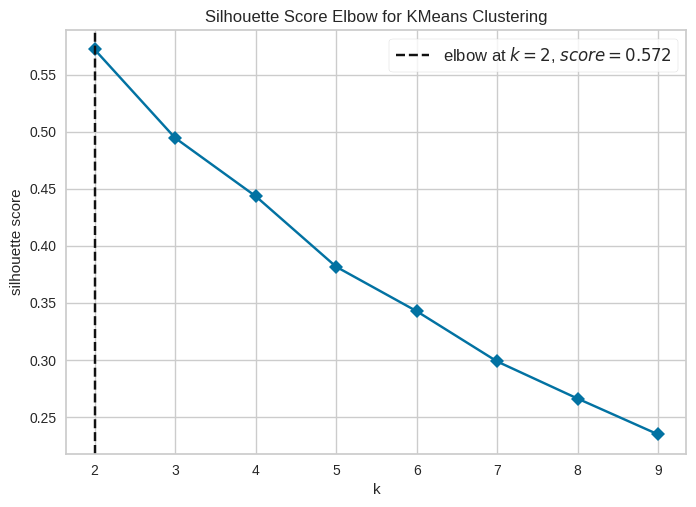

<Axes: title={'center': 'Silhouette Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='silhouette score'>

In [23]:
# Visualizing the Elbow Method using KElbowVisualizer()

model = KMeans()

# Instantiate KElbowVisualizer
# - Enter the model to be used
# - Specify the number of clusters to be tested (range 2 to 10)
# - Specify the evaluation metric

visualizer = KElbowVisualizer(model,
                       k=(2,10),
                       metric='silhouette',
                       timings=False)

# Run (fit) visualizer for data
visualizer.fit(df)
visualizer.show()

In [24]:
# Using the K-Means Clustering algorithm
# Create (instantiate) a KMeans model object
# - Specify the number of clusters (n_clusters)

model = KMeans(n_clusters=2, random_state=42)

# Train (fit) the model with data (df)
model.fit(df)

KMeans(n_clusters=2, random_state=42)

In [25]:
# Saving models using joblib

joblib.dump(model, "model_clustering.h5")

['model_clustering.h5']

In [26]:
# Countes and displays the Silhouette Score value.
# Get the cluster results (labels) from the fitted 'kmeans' model

labels = model.labels_

# Run the function to calculate the silhouette score.
score = silhouette_score(df, labels)

# Print the Score
print("Silhouette Score:", score)

Silhouette Score: 0.5719840690144938


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


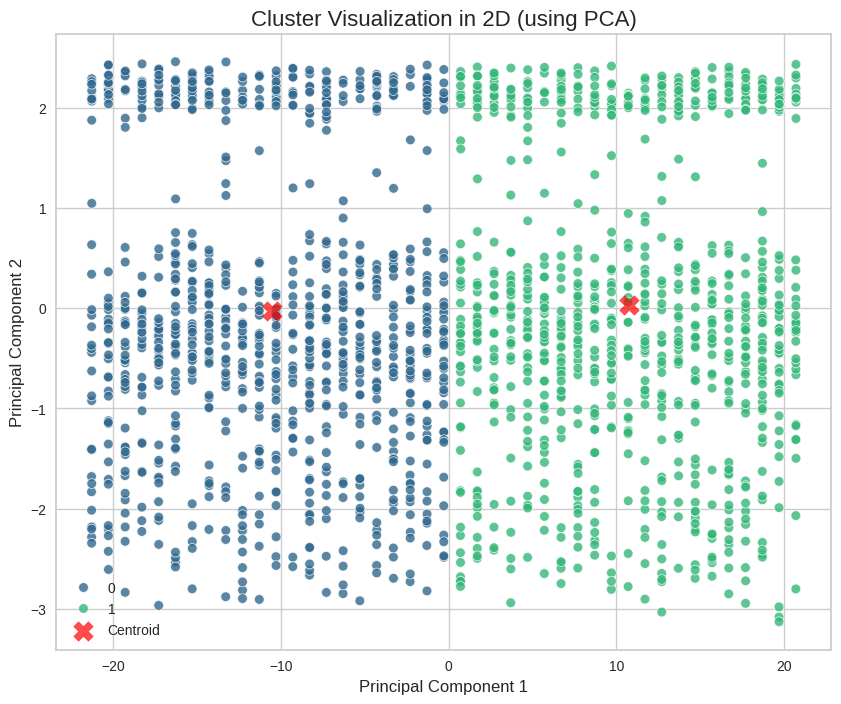

In [27]:
# Creating a visualization of clustering results

# Instantiate a PCA object for 2 components (n_components=2)
pca = PCA(n_components=2)

# Apply (fit) PCA to the data 'df' and transform the data
df_pca = pca.fit_transform(df)
df_pca = np.array(df_pca)

# Create a new DataFrame 'df_pca' from the transformation results
df_pca = pd.DataFrame(data=df_pca, columns=['Principal Component 1', 'Principal Component 2'])

# Add 'Cluster' column to 'df_pca' using 'labels'(variable from previous 'kmeans.labels_' result)
df_pca['Cluster'] = labels

# Create a scatter plot using Seaborn
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='Principal Component 1',
    y='Principal Component 2',
    hue='Cluster',  # Color the dots based on the 'Cluster' column
    palette=sns.color_palette("viridis", n_colors=2),
    data=df_pca,
    legend="full",
    alpha=0.8
)

plt.title('Cluster Visualization in 2D (using PCA)', fontsize=16)
plt.xlabel('Principal Component 1', fontsize=12)
plt.ylabel('Principal Component 2', fontsize=12)
centers = pca.transform(model.cluster_centers_)

centers_arr = np.array(centers)

plt.scatter(centers_arr[:, 0], centers_arr[:, 1], c='red', s=200, alpha=0.7, marker='X', label='Centroid')
plt.legend()
plt.show()

In [28]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# Building a model using PCA.
# Instantiate a PCA object for 2 components (n_components=2)

pca = PCA(n_components=2)

# Apply (fit) PCA to the 'df_used' data and transform the data
df_pca_array = pca.fit_transform(df_used)

# Create a new DataFrame 'final_data' from the PCA array results by taking the values ​​first
final_data = pd.DataFrame(data=df_pca_array, columns=['PCA1', 'PCA2'])

# Create (instantiate) a NEW KMeans model
kmeans_pca = KMeans(n_clusters=2, random_state=42)

# Train (fit) this NEW KMeans model ONLY on 'final_data'
kmeans_pca.fit(final_data)

KMeans(n_clusters=2, random_state=42)

In [29]:
# Save the PCA model for comparison by running this code

joblib.dump(kmeans_pca, "PCA_model_clustering.h5")

['PCA_model_clustering.h5']

# **5. Cluster Interpretation**

In [30]:
# Descriptive analysis of minimum mean, min and max for numeric features.

# Add a new 'Cluster' column in the form of 'labels' (variable from 'kmeans.labels_' previously)
df_used['Cluster'] = labels

# Groupby 'df_used' based on 'Cluster' and calculate aggregation for 'numerical_cols'.
agg_summary = df_used.groupby('Cluster')[numerical_cols].agg(['mean', 'min', 'max']).round(2).T

display(agg_summary)

Cluster                      0     1
TransactionAmount   mean -0.01  0.01
                    min  -1.17 -1.18
                    max   2.96  2.90
CustomerAge         mean  0.02 -0.02
                    min  -1.50 -1.50
                    max   1.99  1.99
TransactionDuration mean  0.03 -0.03
                    min  -1.55 -1.55
                    max   2.56  2.55
LoginAttempts       mean  0.00  0.00
                    min   0.00  0.00
                    max   0.00  0.00
AccountBalance      mean  0.01 -0.01
                    min  -1.28 -1.28
                    max   2.52  2.53

## Interpretation of the characteristics of each cluster based on its range before **Inverse** (still in **Scaled** condition).
1. **CLUSTER 1: Age Maturity, Spending Profile, and Wealth**:
- **Mean of Customer Age : -0.02**
- **Mean of Transaction Duration: -0.03**
- **Mean of Account Balance: -0.01** <Before inversion> <After inversion>
- **Analysis: Based on PCA component values ​​(loadings)**:

- **Principal Component 1 (PC1) is dominated by the 'TransactionAmount' variable, so PC1 represents the [Number of Transactions] indicator. Principal Component 2 (PC2) is dominated by the variables [CustomerAge], [TransactionDuration], and [AccountBalance], so PC2 represents the [Age Demographics and Wealth Profile] indicator.**

- **Thus, Cluster 0, located in the [Top-Left] area, represents the data group with the characteristics [Low Wealth Profile/Younger Age] and [High Number of Transactions], while Cluster 1, located in the [Bottom-Right] area, represents the [High Wealth Profile/Older Age] and [Low Number of Transactions] group.**

# **6. Exporting Data**

In [31]:
# Make changing the clustering column name become to Target.

df_used.rename(columns={"Cluster": "Target"}, inplace=True)

df_used.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,NewCustomerAge,Target
0,-1.111922,1,36,0,1.426636,0,-0.541568,0.0,0.002918,2,1
1,0.546926,1,15,0,1.313889,0,0.308502,0.0,2.216531,2,0
2,-0.597984,1,23,2,-1.448403,3,-0.895763,0.0,-1.018513,1,1
3,-0.331350,1,33,2,-1.053790,3,-1.334965,0.0,0.887895,1,1
5,-0.754364,1,28,0,-1.504776,3,0.747704,0.0,-1.105726,1,1


In [32]:
# Save the clustering data

df_used.to_csv('clustering_data.csv', index=False)

In [33]:
# inverse dataset to normal range for numerical

df_inverse = df_used.copy()

# Use 'scaler' to return 'numerical_cols' to its original value.
df_inverse[numerical_cols] = scaler.inverse_transform(df_inverse[numerical_cols])

df_inverse.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,NewCustomerAge,Target
0,14.09,1,36,0,70.0,0,81.0,1.0,5112.21,2,1
1,376.24,1,15,0,68.0,0,141.0,1.0,13758.91,2,0
2,126.29,1,23,2,19.0,3,56.0,1.0,1122.35,1,1
3,184.50,1,33,2,26.0,3,25.0,1.0,8569.06,1,1
5,92.15,1,28,0,18.0,3,172.0,1.0,781.68,1,1


In [34]:
# inverse the encoded dataset to its original categories.

for column in categorical_cols:
    encoder = encoders[column]
    df_inverse[column] = encoder.inverse_transform(df_inverse[column].astype(int))

df_inverse.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,NewCustomerAge,Target
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21,Senior,1
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91,Senior,0
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35,Child/Teen,1
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06,Child/Teen,1
5,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68,Child/Teen,1


In [35]:
# Descriptive analysis of at least the mean, min, and max for numerical features and the mode for categorical features as in basic, by using the inverted data.

# Groupby 'df_inverse' by 'Target' and calculate aggregation for 'numerical_cols'.
agg_summary_num = df_inverse.groupby('Target')[numerical_cols].agg(['mean', 'min', 'max']).round(2).T

# Group by 'df_inverse' based on 'Target' and calculate the aggregation for 'categorical_cols'.
# - Calculate the aggregation (agg) of 'mode' (the most frequently occurring value).
# - use 'lambda x: x.mode()[0]' to get the first mode value)

agg_summary_cat = df_inverse.groupby('Target')[categorical_cols].agg(lambda x: x.mode()[0]).round(2).T

display(agg_summary_num)
display(agg_summary_cat)

Target                           0         1
TransactionAmount   mean    255.55    258.15
                    min       0.32      0.26
                    max     903.19    889.01
CustomerAge         mean     45.06     44.33
                    min      18.00     18.00
                    max      80.00     80.00
TransactionDuration mean    121.12    117.30
                    min      10.00     10.00
                    max     300.00    299.00
LoginAttempts       mean      1.00      1.00
                    min       1.00      1.00
                    max       1.00      1.00
AccountBalance      mean   5142.17   5058.81
                    min     117.98    102.20
                    max   14942.78  14977.99

Target,0,1
TransactionType,Debit,Debit
Location,Charlotte,Tucson
Channel,Branch,Branch
CustomerOccupation,Doctor,Student
NewCustomerAge,Adult,Child/Teen


## Interpreting the characteristics of each cluster based on its range after **Inverse**.
1. **Cluster 1: Low Transaction Amount and Older Age**:
- **Mean Transaction Amount: US$ 241.09**
- **Mean Customer Age: 45.06 years**<Before inverse> <After inverse>
- **Analysis:** This cluster is Cluster 1, located in the [Bottom-Right] area, representing the [High Age Demographic] and [Low Transaction Amount] groups.

2. **Cluster 0: High Transaction Amount and Younger Age**:
- **Mean Transaction Amount: US$ 246.02**
- **Mean Customer Age: 44.38 years**<Before inverse> <After inverse>
- **Analysis:** This cluster is Cluster 1, located in the [Top-Left] area, representing the [Low Age Demographic] and [High Transaction Amount] groups.

In [36]:
# Recheck the data that has been inverted.

agg_summary_num.head()

Target                       0       1
TransactionAmount mean  255.55  258.15
                  min     0.32    0.26
                  max   903.19  889.01
CustomerAge       mean   45.06   44.33
                  min    18.00   18.00

In [37]:
# Save Inverse Data

df_inverse.to_csv('data_clustering_inverse.csv', index=False)

End of Code.